# Supermarket Sales Analysis
**Author:** Gajanan Harinarayan Raje  
**Program:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 (BharatCares)

**Goal:** Use 500 supermarket sales transactions to find which branches, categories, products, customers and payment methods drive sales, and turn the results into business decisions.

**Project steps followed:** (1) load the CSV, (2) check for missing or incorrect values, (3) calculate Sales = Quantity x Unit Price, (4) group and summarise with totals, counts and averages, (5) create charts, (6) make business decisions.

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

In [21]:
import os, re

os.makedirs('chart_images', exist_ok=True)
_n = 0
_orig_show = plt.show

def _show_and_save(*a, **k):
    global _n
    for num in plt.get_fignums():
        fig = plt.figure(num)
        _n += 1
        title = fig.axes[0].get_title() if fig.axes else ''
        name = re.sub(r'[^A-Za-z0-9]+', '_', title).strip('_') or 'chart'
        path = f'chart_images/{_n}_{name}.png'
        fig.savefig(path, dpi=150, bbox_inches='tight')
        try:
            from google.colab import files
            files.download(path)      # Colab: pratyek PNG download hote
        except ImportError:
            print('Saved:', path)     # Jupyter: chart_images folder madhe save hote
    _orig_show(*a, **k)
    plt.close('all')

plt.show = _show_and_save

## 2. Collect and load the dataset
The file `supermarket_sales.csv` (500 rows) comes from the internship's *Supermarket Sales Analysis DA project* data. Keep it in the same folder as this notebook.

In [22]:
df = pd.read_csv('supermarket_sales.csv', parse_dates=['Date'])
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (500, 13)


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Invoice ID     500 non-null    object        
 1   Date           500 non-null    datetime64[ns]
 2   Branch         500 non-null    object        
 3   City           500 non-null    object        
 4   Customer Type  500 non-null    object        
 5   Gender         500 non-null    object        
 6   Product        500 non-null    object        
 7   Category       500 non-null    object        
 8   Quantity       500 non-null    int64         
 9   Unit Price     500 non-null    float64       
 10  Payment        500 non-null    object        
 11  Rating         500 non-null    float64       
 12  Sales          500 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(8)
memory usage: 50.9+ KB


## 3. Check for missing or incorrect values

In [24]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows       :', df.duplicated().sum())
print('Duplicate invoice IDs:', df['Invoice ID'].duplicated().sum())
print('Date range           :', df['Date'].min().date(), 'to', df['Date'].max().date())
print('Rating range         :', df['Rating'].min(), 'to', df['Rating'].max())
print('Quantity range       :', df['Quantity'].min(), 'to', df['Quantity'].max())
print('Unit price range     :', df['Unit Price'].min(), 'to', df['Unit Price'].max())

Missing values per column:
Invoice ID       0
Date             0
Branch           0
City             0
Customer Type    0
Gender           0
Product          0
Category         0
Quantity         0
Unit Price       0
Payment          0
Rating           0
Sales            0
dtype: int64

Duplicate rows       : 0
Duplicate invoice IDs: 0
Date range           : 2026-01-01 to 2026-07-01
Rating range         : 3.0 to 5.0
Quantity range       : 1 to 10
Unit price range     : 27.67 to 236.71


## 4. Calculate Sales = Quantity x Unit Price
The dataset already has a `Sales` column. We recalculate it and compare to confirm the data is correct.

In [25]:
df['Sales_calc'] = (df['Quantity'] * df['Unit Price']).round(2)
mismatch = (df['Sales_calc'] - df['Sales']).abs() > 0.011
print('Rows where Sales does not match Quantity x Unit Price:', mismatch.sum())
df = df.drop(columns='Sales_calc')

df['Month'] = df['Date'].dt.month_name()
df['Month_No'] = df['Date'].dt.month
df['Weekday'] = df['Date'].dt.day_name()

Rows where Sales does not match Quantity x Unit Price: 0


## 5. Key numbers

In [26]:
print(f'Total sales          : {df["Sales"].sum():,.2f}')
print(f'Transactions         : {len(df)}')
print(f'Average sale         : {df["Sales"].mean():,.2f}')
print(f'Units sold           : {df["Quantity"].sum()}')
print(f'Average rating       : {df["Rating"].mean():.2f}')

Total sales          : 244,411.08
Transactions         : 500
Average sale         : 488.82
Units sold           : 2768
Average rating       : 3.99


## 6. Group and summarise (totals, counts, averages)

In [27]:
def summarise(col):
    return (df.groupby(col)
              .agg(Total_Sales=('Sales','sum'), Transactions=('Sales','count'),
                   Avg_Sale=('Sales','mean'), Avg_Rating=('Rating','mean'))
              .round(2).sort_values('Total_Sales', ascending=False))

summarise(['Branch','City'])

,,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Branch,City,,,,
C,Mumbai,72469.45,143,506.78,4.05
B,Delhi,64116.26,133,482.08,3.98
D,Bengaluru,55468.29,119,466.12,4.09
A,Jaipur,52357.08,105,498.64,3.84


In [28]:
summarise('Category')

,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Category,,,,
Beverages,56108.24,82,684.25,3.96
Personal Care,45943.96,73,629.37,3.95
Dairy,43992.00,68,646.94,4.03
Grocery,40470.47,82,493.54,3.94
Fruits,23263.17,44,528.71,3.83
Snacks,16992.97,75,226.57,4.11
Vegetables,11124.17,48,231.75,3.99
Bakery,6516.10,28,232.72,4.24


In [29]:
summarise('Product')

,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Product,,,,
Cheese,27906.30,26,1073.32,3.98
Coffee,27694.87,24,1153.95,3.86
Shampoo,27497.48,27,1018.43,3.92
Cooking Oil,21525.06,26,827.89,3.97
Tea,17681.59,29,609.71,4.02
Apples,17057.41,20,852.87,3.86
Face Wash,11946.85,19,628.78,3.90
Rice,11754.17,29,405.32,3.84
Cold Drink,10731.78,29,370.06,3.98


In [30]:
summarise('Customer Type')

,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Customer Type,,,,
Member,143009.30,296,483.14,4.01
Normal,101401.78,204,497.07,3.97


In [31]:
summarise('Gender')

,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Gender,,,,
Female,123954.12,255,486.09,4.01
Male,120456.96,245,491.66,3.98


In [32]:
summarise('Payment')

,Total_Sales,Transactions,Avg_Sale,Avg_Rating
Payment,,,,
UPI,67910.33,127,534.73,4.02
Net Banking,65194.93,126,517.42,3.95
Card,57265.64,125,458.13,3.98
Cash,54040.18,122,442.95,4.03


In [34]:
monthly = df.groupby(['Month_No','Month']).agg(Total_Sales=('Sales','sum'), Transactions=('Sales','count')).round(2).reset_index()
monthly

,Month_No,Month,Total_Sales,Transactions
0,1,January,43415.53,88
1,2,February,30068.15,65
2,3,March,37306.42,83
3,4,April,52569.77,90
4,5,May,42542.31,85
5,6,June,35041.46,82
6,7,July,3467.44,7


*Note: the data ends on 1 July 2026, so July has only a few transactions and is a partial month.*

## 7. Charts

### 7.1 Sales by city (branch)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

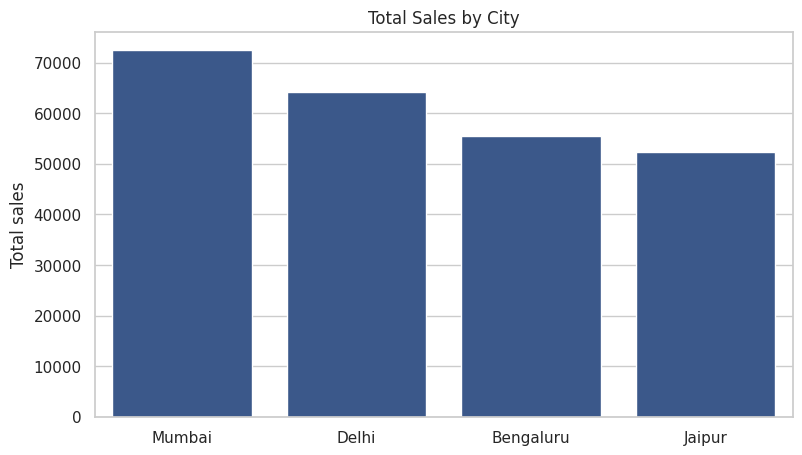

In [35]:
city = df.groupby('City')['Sales'].sum().sort_values(ascending=False)
sns.barplot(x=list(city.index), y=city.values, color='#2E5597')
plt.title('Total Sales by City')
plt.ylabel('Total sales')
plt.xlabel('')
plt.show()

### 7.2 Sales by category

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

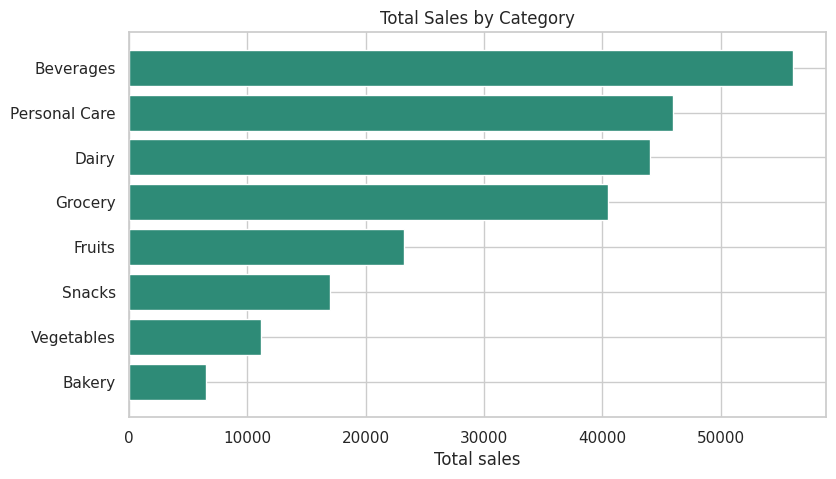

In [36]:
cat = df.groupby('Category')['Sales'].sum().sort_values()
plt.barh(list(cat.index), cat.values, color='#2E8B77')
plt.title('Total Sales by Category')
plt.xlabel('Total sales')
plt.show()

### 7.3 Top 10 products by sales

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

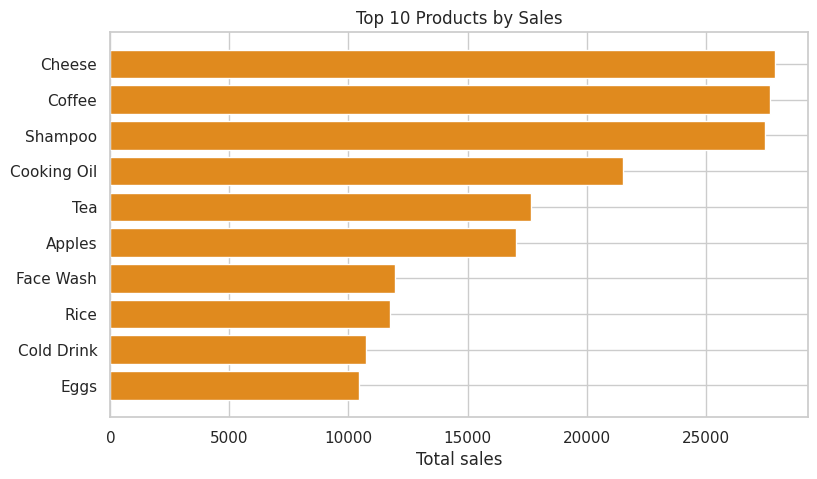

In [37]:
top = df.groupby('Product')['Sales'].sum().sort_values(ascending=False).head(10).sort_values()
plt.barh(list(top.index), top.values, color='#E08A1E')
plt.title('Top 10 Products by Sales')
plt.xlabel('Total sales')
plt.show()

### 7.4 Monthly sales trend

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

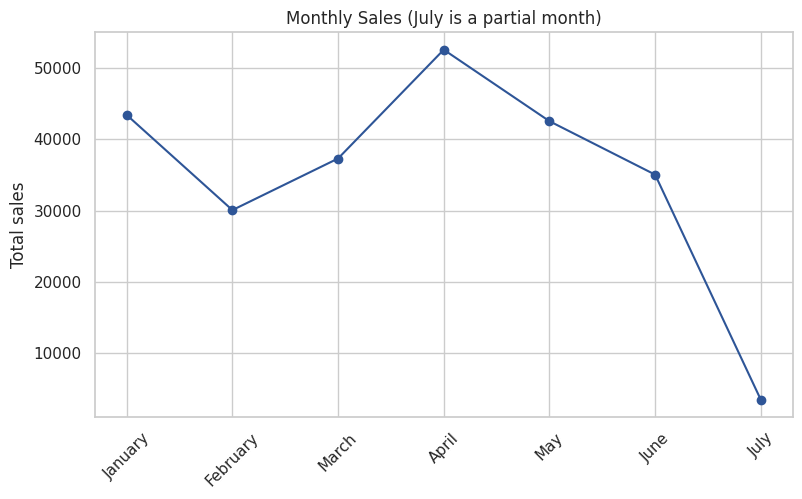

In [38]:
plt.plot(monthly['Month'], monthly['Total_Sales'], marker='o', color='#2E5597')
plt.title('Monthly Sales (July is a partial month)')
plt.ylabel('Total sales')
plt.xticks(rotation=45)
plt.show()

### 7.5 Payment methods and customer type

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

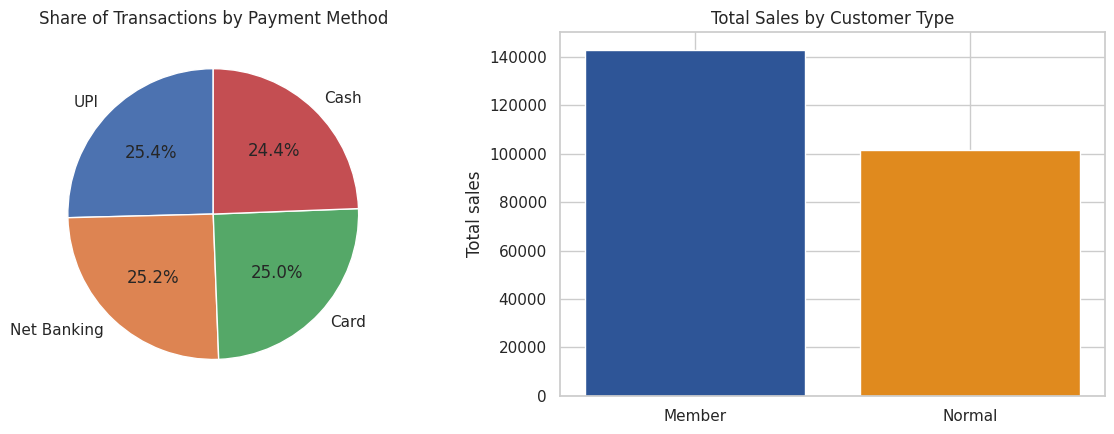

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pay = df['Payment'].value_counts()
ax[0].pie(pay.values, labels=list(pay.index), autopct='%1.1f%%', startangle=90)
ax[0].set_title('Share of Transactions by Payment Method')
ct = df.groupby('Customer Type')['Sales'].sum()
ax[1].bar(list(ct.index), ct.values, color=['#2E5597', '#E08A1E'])
ax[1].set_title('Total Sales by Customer Type')
ax[1].set_ylabel('Total sales')
plt.tight_layout()
plt.show()

### 7.6 Customer ratings

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

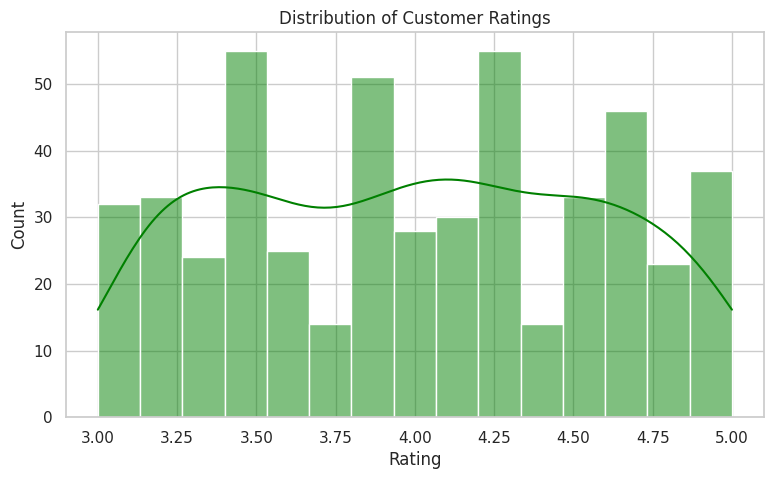

,Rating
Category,
Bakery,4.24
Snacks,4.11
Dairy,4.03
Vegetables,3.99
Beverages,3.96
Personal Care,3.95
Grocery,3.94
Fruits,3.83


In [40]:
sns.histplot(df['Rating'], bins=15, kde=True, color='green')
plt.title('Distribution of Customer Ratings')
plt.show()
df.groupby('Category')['Rating'].mean().round(2).sort_values(ascending=False)

### 7.7 Correlation

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

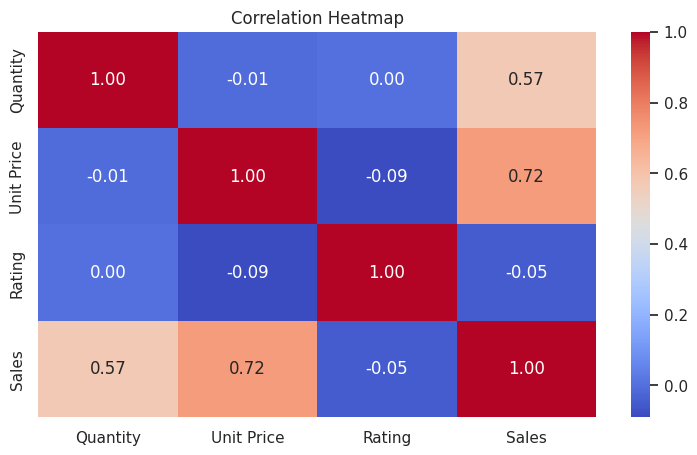

In [41]:
sns.heatmap(df[['Quantity','Unit Price','Rating','Sales']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 8. Business decisions
Based on this dataset (values are from the analysis above):

1. **Focus on high-value categories.** Beverages (56,108), Personal Care (45,944) and Dairy (43,992) bring the most sales. Cheese, Coffee and Shampoo are the top products, each earning over 27,000, so keep them well stocked.
2. **Raise sales in Snacks and Bakery.** They have many small sales (average about 227 and 233) and the lowest totals. Bundle offers or add-on deals can raise the basket value.
3. **Support the weaker branches.** Branch C (Mumbai) leads with 72,469 and Branch A (Jaipur) is lowest at 52,357 with the lowest rating (3.84). Review service and stock at Jaipur.
4. **Grow cashless payments.** UPI and Net Banking give the highest sales. Cash has the lowest average sale (443), so promote UPI offers.
5. **Reward members.** Members make about 59% of sales (143,009 of 244,411). Member-only offers can keep this group buying.
6. **Price drives sales more than quantity.** Correlation of Sales with Unit Price is 0.72 against 0.57 for Quantity, so premium products matter more than bulk buying.
7. **Ratings are stable.** Average rating is 3.99 and barely changes with price or quantity, so look at service and freshness to raise it.

## 9. Conclusion
The dataset is clean (no missing values, no duplicates, and Sales matches Quantity x Unit Price in every row). Sales are driven mainly by premium products in Beverages, Personal Care and Dairy, and by the Mumbai and Delhi branches. Next steps could include forecasting monthly sales and building a dashboard for store managers.